[Project Details](https://docs.google.com/document/d/1yJbsty_9ebmV0zXpsrc02Q1w8UoZQ_A_qL6Zv7haIPc/edit?usp=sharing)

My Portion: Inverse Camera to Ball Position Algorithm

In [194]:
settings = "4K"
if settings == "1080p iphone":
  # initialize parameter values of a 1080p iphone video
  width = 1920
  height = 1080
  focalLength = 0.00676  # 6.76 mm physical focal length (24 mm equivalent)
  p_x = 0.0000048        # 4.8 µm effective pixel pitch at 1080p
  p_y = 0.0000048
  alpha = focalLength / p_x  # ~1408 px
  beta = focalLength / p_y   # ~1408 px
  u_0 = width // 2           # 960
  v_0 = height // 2          # 540
  R_ball = 0.119 # 0.119 m for standard NBA men's size 7 ball
elif settings == "4K":
  # initialize parameter values of a 4K video
  width = 3840
  height = 2160
  focalLength = 0.00676  # 6.76 mm physical focal length (24 mm equivalent)
  p_x = 0.0000024       # 2.4 µm effective pixel pitch at 1080p
  p_y = 0.0000024
  alpha = focalLength / p_x  # ~2817 px
  beta = focalLength / p_y   # ~2817 px
  u_0 = width // 2           # 1920
  v_0 = height // 2          # 1080
  R_ball = 0.119 # 0.119 m for standard NBA men's size 7 ball

In [208]:
import numpy as np

def randomProjectedSphere(width, height, alpha, beta, u_0, v_0, R_ball, dropRate, min_pixels=10):
    rng = np.random.default_rng()

    # Exact camera frustum limits in normalized coordinates
    max_x_ratio = u_0 / alpha
    max_y_ratio = v_0 / beta

    while True:
        # 1. Pick a random true 3D ball center guaranteed to be inside the camera FOV
        z_c = rng.uniform(2.5, 30)
        x_c = rng.uniform(-max_x_ratio * z_c, max_x_ratio * z_c)
        y_c = rng.uniform(-max_y_ratio * z_c, max_y_ratio * z_c)
        p_c = np.array([x_c, y_c, z_c])

        # 2. Compute the 3D tangent circle (silhouette) on the sphere
        d = np.linalg.norm(p_c)
        c_hat = p_c / d
        cos_theta = np.sqrt(1 - (R_ball / d)**2)

        ring_center = (d * cos_theta**2) * c_hat
        ring_radius = R_ball * cos_theta

        # Build two orthonormal basis vectors (e1, e2) perpendicular to c_hat
        ref = np.array([1.0, 0.0, 0.0]) if abs(c_hat[0]) < 0.9 else np.array([0.0, 1.0, 0.0])
        e1 = np.cross(c_hat, ref)
        e1 /= np.linalg.norm(e1)
        e2 = np.cross(c_hat, e1)

        # 3. Sample 3D points on the silhouette and project to 2D pixels
        angles = rng.uniform(0, 2 * np.pi, size=int(150 * (1 - dropRate)))
        pts_3d = ring_center + ring_radius * (np.outer(np.cos(angles), e1) + np.outer(np.sin(angles), e2))

        u = np.round(alpha * (pts_3d[:, 0] / pts_3d[:, 2]) + u_0).astype(int)
        v = np.round(beta * (pts_3d[:, 1] / pts_3d[:, 2]) + v_0).astype(int)

        valid = (u >= 0) & (u < width) & (v >= 0) & (v < height)

        # Retry if too few pixels landed inside the image
        if np.sum(valid) >= min_pixels:
            circle = np.column_stack((v[valid], u[valid]))  # [[v, u], ...]
            image = np.zeros((height, width), dtype=np.uint8)
            image[v[valid], u[valid]] = 255

            # Ground-truth projected 2D center of the 3D sphere
            true_center_uv = np.round([alpha * (x_c / z_c) + u_0, beta * (y_c / z_c) + v_0]).astype(int)
            return p_c, true_center_uv, circle, np.stack([image]*3, axis=-1)

ballCoords, center, BasketballCircumferencePixels, image = randomProjectedSphere(width, height, alpha, beta, u_0, v_0, R_ball, 0.8)

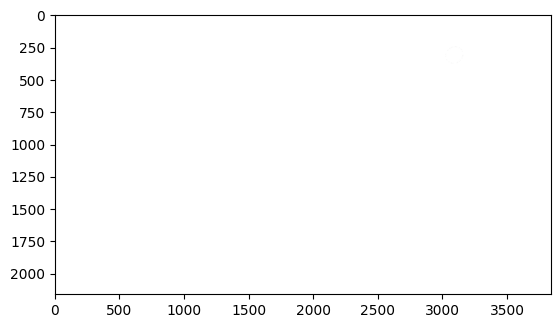

In [209]:
import matplotlib.pyplot as plt
inverted_image = 255 - image
plt.imshow(inverted_image)
plt.show()

In [210]:
# make rays
rays_x = (BasketballCircumferencePixels[:, 1] - u_0)/alpha
rays_y = (BasketballCircumferencePixels[:, 0] - v_0)/beta
rays_z = np.ones_like(rays_x)
rays = np.column_stack((rays_x, rays_y, rays_z))
# normalize rays
norms = np.linalg.norm(rays, axis=1, keepdims=True)
norm_rays = rays / norms

In [219]:
from scipy.optimize import least_squares

def circle_residuals(params, x, y):
    xc, yc, r = params
    distances = np.sqrt((x - xc)**2 + (y - yc)**2)
    return distances - r

# Option 1: Fit 2D circle through 3D points
norm_rays_mean = np.mean(norm_rays, axis=0)
normalized_rays = norm_rays - norm_rays_mean
U, S, V_T = np.linalg.svd(normalized_rays)
normalized_rays_x = normalized_rays @ V_T.T[:, 0]
normalized_rays_y = normalized_rays @ V_T.T[:, 1]
# Kasa's algorithm to approximately fit circle through points
A = np.column_stack((normalized_rays_x, normalized_rays_y, np.ones_like(normalized_rays_x)))
b = normalized_rays_x**2 + normalized_rays_y**2
c, _, _, _ = np.linalg.lstsq(A, b, rcond=None)
xc = c[0] / 2.0
yc = c[1] / 2.0
r = np.sqrt(c[2] + xc**2 + yc**2)
result = least_squares(circle_residuals, x0=[xc, yc, r], args=(normalized_rays_x, normalized_rays_y), method='lm')
xc_fit, yc_fit, r_fit = result.x
center_ray = norm_rays_mean + xc_fit * V_T.T[:, 0] + yc_fit * V_T.T[:, 1]
mag = np.linalg.norm(center_ray)
camera_ray = R_ball/np.sqrt(1 - mag**2)*center_ray/mag

In [217]:
# Option 2: Fit cone through 3D points
ones = np.ones_like(rays_x)
# center_ray, _, _, _ = np.linalg.lstsq(norm_rays, ones)
center_ray = np.linalg.inv(norm_rays.T @ norm_rays)@norm_rays.T@ones
costheta = 1/np.linalg.norm(center_ray)
sintheta = np.sqrt(1 - costheta*costheta)
camera_ray = R_ball/sintheta*center_ray/np.linalg.norm(center_ray) # in meters

In [220]:
# test for option 1 and 2: project back to u, v space
mat = np.array([[alpha, 0, u_0], [0, beta, v_0]])
test_center = np.round(mat @ center_ray/center_ray[-1]).astype(int)
print("Actual coords:", ballCoords, "m")
print("Test coords:", camera_ray, "m")
print("Diff: ", ballCoords - camera_ray, "m")
print("Error: ", np.linalg.norm(ballCoords - camera_ray), "m")

Actual coords: [ 2.2538919  -1.478998    5.45206727] m
Test coords: [ 2.25469347 -1.479348    5.45387423] m
Diff:  [-0.00080157  0.00035    -0.00180696] m
Error:  0.002007511377936342 m
